# 最小二乗法を射影として理解する

## 概要

最小二乗法は、観測ベクトルを説明変数の列空間に直交射影する計算である。直線への射影から正規方程式を導き、3点の回帰を手計算とPythonで確かめる。残差が何に直交するのかを図で確認することが目的である。

## 実行環境

仮想環境・カーネルは `wa-src(3.14.6)`、Pythonは `3.14.6` である。使用ライブラリの版は次のセルで表示する。上から順に実行すると、図を `102_nb_files` にSVGで保存し、出力欄にも埋め込む。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
import base64
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Latex, display
from matplotlib.ticker import FuncFormatter, MaxNLocator

assert sys.version_info[:3] == (3, 14, 6)
print('実行環境: wa-src(3.14.6)')
print(f'Python: {platform.python_version()}')
print(f'NumPy: {np.__version__}, Matplotlib: {matplotlib.__version__}')

# 桁数は小数点以下の桁数ではなく、有効数字で指定する。
def sig3(value):
    return format(float(value), '#.3g')


np.set_printoptions(formatter={'float_kind': sig3})
plt.rcParams.update({'font.size': 11, 'axes.grid': True,
                     'grid.alpha': 0.250, 'svg.fonttype': 'none'})
output_dir = Path('102_nb_files')
output_dir.mkdir(exist_ok=True)


def save_svg(fig, filename):
    # 軸目盛りも有効数字3桁にそろえる。ファイルと出力欄に同じ図を使う。
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(FuncFormatter(lambda v, _: sig3(v)))
        if hasattr(ax, 'zaxis'):
            ax.zaxis.set_major_formatter(FuncFormatter(lambda v, _: sig3(v)))
    path = output_dir / filename
    fig.savefig(path, format='svg', bbox_inches='tight')
    plt.close(fig)
    # HTML表示では出力欄の幅に合わせる。SVG自体もノートブックに保持する。
    svg = path.read_text(encoding='utf-8')
    encoded = base64.b64encode(svg.encode('utf-8')).decode('ascii')
    display({'image/svg+xml': svg, 'text/html': (
        f'<img src="data:image/svg+xml;base64,{encoded}" '
        f'alt="{filename}" style="max-width:100%;height:auto;">'
    )}, raw=True)

実行環境: wa-src(3.14.6)
Python: 3.14.6
NumPy: 2.5.4, Matplotlib: 3.11.2


## 1. 直線への射影

ゼロでないベクトル $\mathbf{a}$ が張る直線上の点は $t\mathbf{a}$ と書ける。観測 $\mathbf{y}$ に最も近い点を、距離の二乗を最小にして求める。

$$
\begin{aligned}
f(t)&=\|\mathbf{y}-t\mathbf{a}\|^2\\
&=(\mathbf{y}-t\mathbf{a})^T(\mathbf{y}-t\mathbf{a})\\
&=\mathbf{y}^T\mathbf{y}-2t\mathbf{a}^T\mathbf{y}+t^2\mathbf{a}^T\mathbf{a},\\
f'(t)&=-2\mathbf{a}^T\mathbf{y}+2t\mathbf{a}^T\mathbf{a}=0,\\
\hat t&=\frac{\mathbf{a}^T\mathbf{y}}{\mathbf{a}^T\mathbf{a}}.
\end{aligned}
$$

$f''(t)=2\mathbf{a}^T\mathbf{a}>0$ なので最小点である。射影を $\hat{\mathbf{y}}=\hat t\mathbf{a}$、残差を $\mathbf{r}=\mathbf{y}-\hat{\mathbf{y}}$ とすると、

$$
\mathbf{a}^T\mathbf{r}
=\mathbf{a}^T\mathbf{y}
-\frac{\mathbf{a}^T\mathbf{y}}{\mathbf{a}^T\mathbf{a}}\mathbf{a}^T\mathbf{a}=0.
$$

つまり、残差と直線は直交する。$\mathbf{a}=(1,1)^T$、$\mathbf{y}=(2,0)^T$ なら $\hat t=2/2=1$、$\hat{\mathbf{y}}=(1,1)^T$、$\mathbf{r}=(1,-1)^T$ となる。この例では $f(t)=(2-t)^2+t^2=2(t-1)^2+2$ である。

{'t': '1.00',
 '内積': '0.00',
 '射影': array([1.00, 1.00]),
 '残差': array([1.00, -1.00])}


<IPython.core.display.Latex object>

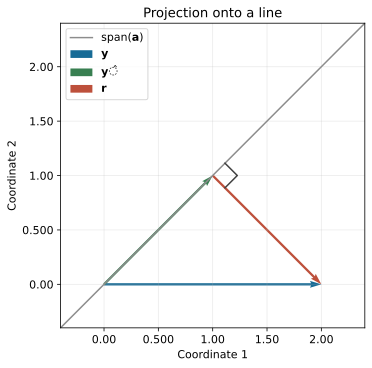

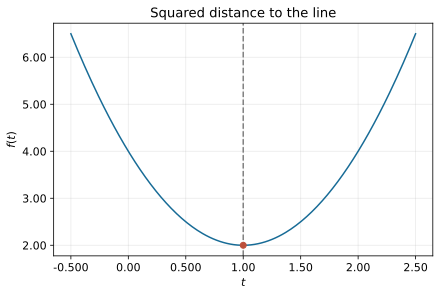

In [2]:
a = np.array([1, 1])
y_line = np.array([2, 0])
t_hat = (a @ y_line) / (a @ a)
yhat_line = t_hat * a
r_line = y_line - yhat_line
pprint({'t': sig3(t_hat), '射影': yhat_line, '残差': r_line,
        '内積': sig3(a @ r_line)})
display(Latex(r'\(\boxed{\hat{\mathbf{y}}='
              r'\mathbf{a}\frac{\mathbf{a}^T\mathbf{y}}'
              r'{\mathbf{a}^T\mathbf{a}}},\quad'
              r'\mathbf{a}^T\mathbf{r}=0\)'))

fig, ax = plt.subplots(figsize=(6, 5), layout='constrained')
line = np.linspace(-0.400, 2.40, 100)
ax.plot(line, line, color='0.550', label=r'$\mathrm{span}(\mathbf{a})$')
for vector, color, label in [
    (y_line, '#176b96', r'$\mathbf{y}$'),
    (yhat_line, '#387f51', r'$\hat{\mathbf{y}}$'),
]:
    ax.quiver(0, 0, *vector, angles='xy', scale_units='xy', scale=1,
              color=color, label=label)
ax.quiver(*yhat_line, *r_line, angles='xy', scale_units='xy', scale=1,
          color='#bd503b', label=r'$\mathbf{r}$')
# 射影点に直角の印を置く。
u = a / np.linalg.norm(a) * 0.160
v = r_line / np.linalg.norm(r_line) * 0.160
corner = np.array([yhat_line + u, yhat_line + u + v, yhat_line + v])
ax.plot(corner[:, 0], corner[:, 1], color='0.250')
ax.set(xlim=(-0.400, 2.40), ylim=(-0.400, 2.40),
       xlabel='Coordinate 1', ylabel='Coordinate 2', title='Projection onto a line')
ax.set_aspect('equal')
ax.legend(loc='upper left')
save_svg(fig, '01_line_projection.svg')

trial_t = np.linspace(-0.500, 2.50, 200)
loss_line = np.sum((y_line - trial_t[:, None] * a)**2, axis=1)
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
ax.plot(trial_t, loss_line, color='#176b96')
ax.scatter([t_hat], [r_line @ r_line], color='#bd503b', zorder=3)
ax.axvline(t_hat, color='0.500', linestyle='--')
ax.set(xlabel='$t$', ylabel='$f(t)$', title='Squared distance to the line')
save_svg(fig, '02_scalar_loss.svg')

## 2. 列空間と正規方程式

$\mathbf{X}\in\mathbb{R}^{n\times p}$、$\mathbf{b}\in\mathbb{R}^p$、$\mathbf{y}\in\mathbb{R}^n$ とする。$\mathbf{X}\mathbf{b}$ は列ベクトルの線形結合であり、その全体が列空間である。ここでは列が一次独立と仮定する。

$$
\begin{aligned}
S(\mathbf{b})&=\|\mathbf{y}-\mathbf{X}\mathbf{b}\|^2\\
&=\mathbf{y}^T\mathbf{y}-\mathbf{y}^T\mathbf{X}\mathbf{b}
-\mathbf{b}^T\mathbf{X}^T\mathbf{y}
+\mathbf{b}^T\mathbf{X}^T\mathbf{X}\mathbf{b}\\
&=\mathbf{y}^T\mathbf{y}-2\mathbf{b}^T\mathbf{X}^T\mathbf{y}
+\mathbf{b}^T\mathbf{X}^T\mathbf{X}\mathbf{b},\\
\nabla S&=-2\mathbf{X}^T\mathbf{y}+2\mathbf{X}^T\mathbf{X}\mathbf{b}.
\end{aligned}
$$

中央の2項は同じスカラーなのでまとめた。微分をゼロにすると正規方程式を得る。

$$
\mathbf{X}^T\mathbf{X}\hat{\mathbf{b}}=\mathbf{X}^T\mathbf{y}
\quad\Longleftrightarrow\quad
\mathbf{X}^T(\mathbf{y}-\mathbf{X}\hat{\mathbf{b}})=\mathbf{0}.
$$

残差は各列に直交するため、列空間のどのベクトルにも直交する。私には、係数の公式だけより、この直交条件を併せて見る方が理解しやすい。

最小になることも確認する。任意の係数を $\hat{\mathbf{b}}+\mathbf{d}$ と書けば、

$$
\begin{aligned}
S(\hat{\mathbf{b}}+\mathbf{d})
&=\|\mathbf{r}-\mathbf{X}\mathbf{d}\|^2\\
&=\|\mathbf{r}\|^2-2\mathbf{d}^T\mathbf{X}^T\mathbf{r}+\|\mathbf{X}\mathbf{d}\|^2\\
&=S(\hat{\mathbf{b}})+\|\mathbf{X}\mathbf{d}\|^2\ge S(\hat{\mathbf{b}}).
\end{aligned}
$$

列が一次独立なら等号は $\mathbf{d}=\mathbf{0}$ のときだけであり、係数も一意である。ここまでに誤差の正規分布などの確率的な仮定は必要ない。

## 3. 射影行列

$\mathbf{G}=\mathbf{X}^T\mathbf{X}$ と置くと、正規方程式から次を得る。

$$
\hat{\mathbf{b}}=\mathbf{G}^{-1}\mathbf{X}^T\mathbf{y},\qquad
\hat{\mathbf{y}}=\mathbf{P}\mathbf{y},\qquad
\mathbf{P}=\mathbf{X}\mathbf{G}^{-1}\mathbf{X}^T.
$$

$\mathbf{G}^T=\mathbf{G}$ より逆行列も対称である。したがって、

$$
\begin{aligned}
\mathbf{P}^T&=\mathbf{X}(\mathbf{G}^{-1})^T\mathbf{X}^T=\mathbf{P},\\
\mathbf{P}^2&=\mathbf{X}\mathbf{G}^{-1}(\mathbf{X}^T\mathbf{X})\mathbf{G}^{-1}\mathbf{X}^T\\
&=\mathbf{X}\mathbf{G}^{-1}\mathbf{G}\mathbf{G}^{-1}\mathbf{X}^T=\mathbf{P}.
\end{aligned}
$$

$\mathbf{P}^2=\mathbf{P}$ は、射影した点を再び射影しても動かないことを表す。また $\mathbf{y}=\hat{\mathbf{y}}+\mathbf{r}$ と $\hat{\mathbf{y}}^T\mathbf{r}=0$ から、

$$
\|\mathbf{y}\|^2=\|\hat{\mathbf{y}}\|^2+2\hat{\mathbf{y}}^T\mathbf{r}+\|\mathbf{r}\|^2
=\|\hat{\mathbf{y}}\|^2+\|\mathbf{r}\|^2.
$$

In [3]:
# 重要な式をLaTeXの出力として表示する。
display(Latex(r'\(\boxed{\hat{\mathbf{y}}=\mathbf{P}\mathbf{y}},\quad'
              r'\boxed{\mathbf{X}^T\mathbf{r}=\mathbf{0}},\quad'
              r'\mathbf{P}^T=\mathbf{P},\quad\mathbf{P}^2=\mathbf{P}\)'))

<IPython.core.display.Latex object>

## 4. 3点の回帰を計算する

$(x_i,y_i)=(0,1),(1,2),(2,2)$ に $y_i\approx b_0+b_1x_i$ を当てはめる。

$$
\mathbf{X}=\begin{bmatrix}1&0\\1&1\\1&2\end{bmatrix},\quad
\mathbf{y}=\begin{bmatrix}1\\2\\2\end{bmatrix},\quad
\mathbf{X}^T\mathbf{X}=\begin{bmatrix}3&3\\3&5\end{bmatrix},\quad
\mathbf{X}^T\mathbf{y}=\begin{bmatrix}5\\6\end{bmatrix}.
$$

正規方程式は $3b_0+3b_1=5$、$3b_0+5b_1=6$ である。第2式から第1式を引くと $2b_1=1$。よって $b_1=1/2$、$b_0=(5-3/2)/3=7/6$ となる。

$$
\hat{\mathbf{y}}=\begin{bmatrix}7/6\\5/3\\13/6\end{bmatrix},\quad
\mathbf{r}=\begin{bmatrix}-1/6\\1/3\\-1/6\end{bmatrix},\quad
\mathbf{X}^T\mathbf{r}=\begin{bmatrix}-1/6+1/3-1/6\\1/3-2/6\end{bmatrix}=\mathbf{0}.
$$

残差平方和は $1/36+1/9+1/36=1/6$ である。数値計算には `lstsq` を使う。射影行列は小さな例なので明示的に作るが、逆行列を計算せず連立方程式を解く。

In [4]:
x = np.arange(3)
X = np.column_stack([np.ones(3), x])
y = np.array([1, 2, 2])
b_hat = np.linalg.lstsq(X, y, rcond=None)[0]
y_hat = X @ b_hat
residual = y - y_hat
rss = residual @ residual
P = X @ np.linalg.solve(X.T @ X, X.T)

pprint({'係数 [切片, 傾き]': b_hat, '予測値': y_hat,
        '残差': residual, '残差平方和': sig3(rss), '射影行列': P})
display(Latex(
    rf'\(\hat{{\mathbf{{b}}}}=\begin{{bmatrix}}{sig3(b_hat[0])}\\'
    rf'{sig3(b_hat[1])}\end{{bmatrix}},\quad S={sig3(rss)}\)'
))

# 手計算との一致と射影の性質を、丸める前の数値で検証する。
np.testing.assert_allclose(b_hat, [7 / 6, 1 / 2], atol=1.00e-12)
np.testing.assert_allclose(X.T @ residual, 0, atol=1.00e-12)
np.testing.assert_allclose(P.T, P, atol=1.00e-12)
np.testing.assert_allclose(P @ P, P, atol=1.00e-12)
np.testing.assert_allclose(P @ y, y_hat, atol=1.00e-12)
np.testing.assert_allclose(rss, 1 / 6, atol=1.00e-12)
np.testing.assert_allclose(y @ y, y_hat @ y_hat + rss, atol=1.00e-12)
pprint({'直交条件の誤差': sig3(np.linalg.norm(X.T @ residual)),
        '再射影の誤差': sig3(np.linalg.norm(P @ y_hat - y_hat))})
print('手計算・直交性・対称性・冪等性・平方ノルムの分解を確認した。')

{'予測値': array([1.17, 1.67, 2.17]),
 '係数 [切片, 傾き]': array([1.17, 0.500]),
 '射影行列': array([[0.833, 0.333, -0.167],
       [0.333, 0.333, 0.333],
       [-0.167, 0.333, 0.833]]),
 '残差': array([-0.167, 0.333, -0.167]),
 '残差平方和': '0.167'}


<IPython.core.display.Latex object>

{'再射影の誤差': '0.00', '直交条件の誤差': '2.67e-15'}
手計算・直交性・対称性・冪等性・平方ノルムの分解を確認した。


### 回帰図と列空間の図

回帰図の縦の差が残差である。観測を並べた3次元空間では、列空間は原点を通る平面となり、残差はその平面に垂直になる。回帰図の直線に対する最短距離を測っているわけではない。この二つの図は区別しておきたい。

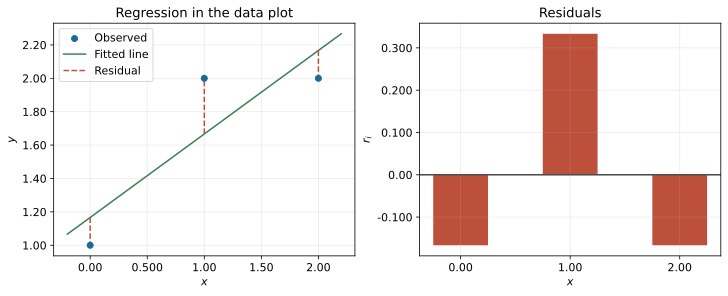

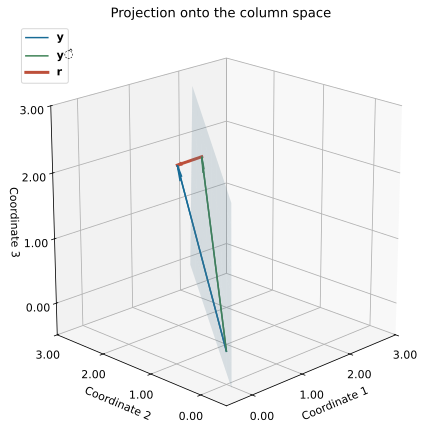

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
x_line = np.linspace(-0.200, 2.20, 100)
axes[0].scatter(x, y, color='#176b96', label='Observed', zorder=3)
axes[0].plot(x_line, b_hat[0] + b_hat[1] * x_line,
             color='#387f51', label='Fitted line')
axes[0].vlines(x, y_hat, y, color='#bd503b', linestyle='--', label='Residual')
axes[0].set(xlabel='$x$', ylabel='$y$', title='Regression in the data plot')
axes[0].legend()
axes[1].bar(x, residual, color='#bd503b', width=0.500)
axes[1].axhline(0, color='0.300')
axes[1].set(xlabel='$x$', ylabel='$r_i$', title='Residuals', xticks=x)
save_svg(fig, '03_regression_residuals.svg')

# 平面をXの2列の線形結合として作る。
c0, c1 = np.meshgrid(np.linspace(-0.200, 1.60, 9),
                     np.linspace(-0.100, 0.700, 9))
plane = c0[..., None] * X[:, 0] + c1[..., None] * X[:, 1]
fig = plt.figure(figsize=(7, 6), layout='constrained')
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(plane[:, :, 0], plane[:, :, 1], plane[:, :, 2],
                alpha=0.200, color='#72a0bb', edgecolor='none')
for vector, color, label in [
    (y, '#176b96', r'$\mathbf{y}$'),
    (y_hat, '#387f51', r'$\hat{\mathbf{y}}$'),
]:
    ax.quiver(0, 0, 0, *vector, color=color, arrow_length_ratio=0.0800)
    ax.plot([0, vector[0]], [0, vector[1]], [0, vector[2]], color=color, label=label)
ax.quiver(*y_hat, *residual, color='#bd503b', arrow_length_ratio=0.200)
ax.plot([y_hat[0], y[0]], [y_hat[1], y[1]], [y_hat[2], y[2]],
        color='#bd503b', linewidth=3, label=r'$\mathbf{r}$')
ax.set(xlabel='Coordinate 1', ylabel='Coordinate 2', zlabel='Coordinate 3',
       title='Projection onto the column space')
# 各軸を同じ尺度にし、残差が視線方向に重ならない角度を選ぶ。
ax.set(xlim=(-0.500, 3), ylim=(-0.500, 3), zlim=(-0.500, 3))
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_major_locator(MaxNLocator(nbins=4))
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=20, azim=-135)
ax.legend(loc='upper left')
save_svg(fig, '04_projection_plane.svg')

### 係数を動かしたときの増加分

この例では $\|\mathbf{X}\mathbf{d}\|^2=3d_0^2+6d_0d_1+5d_1^2$ である。左図は残差平方和の等高線、右図は切片を推定値に固定した断面である。

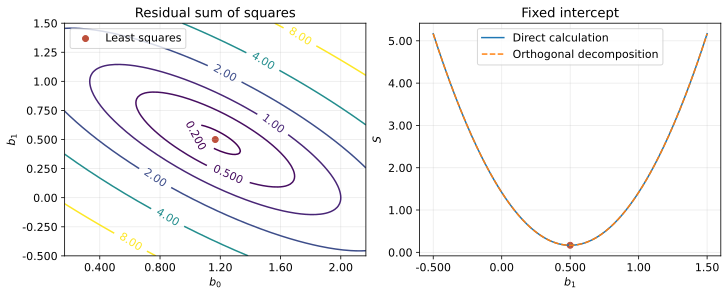

In [6]:
b0, b1 = np.meshgrid(np.linspace(b_hat[0] - 1, b_hat[0] + 1, 121),
                     np.linspace(b_hat[1] - 1, b_hat[1] + 1, 121))
loss = np.sum((y - b0[..., None] - b1[..., None] * x)**2, axis=-1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
contours = axes[0].contour(b0, b1, loss, levels=[0.200, 0.500, 1, 2, 4, 8])
axes[0].clabel(contours, fmt=sig3)
axes[0].scatter(*b_hat, color='#bd503b', label='Least squares')
axes[0].set(xlabel='$b_0$', ylabel='$b_1$', title='Residual sum of squares')
axes[0].legend()
trial_b1 = np.linspace(b_hat[1] - 1, b_hat[1] + 1, 200)
section = np.sum((y - b_hat[0] - trial_b1[:, None] * x)**2, axis=1)
axes[1].plot(trial_b1, section, label='Direct calculation')
axes[1].plot(trial_b1, rss + 5 * (trial_b1 - b_hat[1])**2,
             linestyle='--', label='Orthogonal decomposition')
axes[1].scatter([b_hat[1]], [rss], color='#bd503b')
axes[1].set(xlabel='$b_1$', ylabel='$S$', title='Fixed intercept')
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
save_svg(fig, '05_loss_contours.svg')

## 5. QR分解と列が重複する場合

列が一次独立なら、薄いQR分解 $\mathbf{X}=\mathbf{Q}\mathbf{R}$ で $\mathbf{Q}^T\mathbf{Q}=\mathbf{I}$ となる。正規方程式に代入すると、

$$
\mathbf{R}^T\mathbf{R}\hat{\mathbf{b}}=\mathbf{R}^T\mathbf{Q}^T\mathbf{y}
\ \Longrightarrow\ \mathbf{R}\hat{\mathbf{b}}=\mathbf{Q}^T\mathbf{y}
\ \Longrightarrow\ \hat{\mathbf{y}}=\mathbf{Q}\mathbf{Q}^T\mathbf{y}.
$$

正規方程式では2ノルムの条件数が二乗されるため、通常は `lstsq` やQR分解を使う。列が重複すると係数は一意でないが、射影された予測値は一意である。下では $\mathbf{X}$ に同じ $x$ 列を追加する。`lstsq` は最小ノルムの係数を返す。

{'QRによる係数': array([1.17, 0.500]),
 '列が重複した行列の階数': 2,
 '同じ予測値を与える別の係数': array([1.17, 1.25, -0.750]),
 '最小ノルムの係数': array([1.17, 0.250, 0.250])}


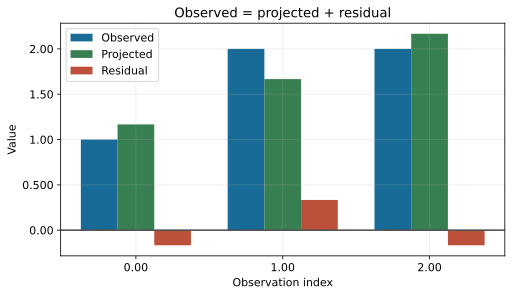

In [7]:
Q, R = np.linalg.qr(X, mode='reduced')
b_qr = np.linalg.solve(R, Q.T @ y)
P_qr = Q @ Q.T
np.testing.assert_allclose(b_qr, b_hat, atol=1.00e-12)
np.testing.assert_allclose(P_qr, P, atol=1.00e-12)

# 2本の同じ列への係数の配分を変えても、予測値は変わらない。
X_duplicate = np.column_stack([X, x])
b_min = np.linalg.lstsq(X_duplicate, y, rcond=None)[0]
b_other = b_min + np.array([0, 1, -1])
np.testing.assert_allclose(X_duplicate @ b_min, y_hat, atol=1.00e-12)
np.testing.assert_allclose(X_duplicate @ b_other, y_hat, atol=1.00e-12)
pprint({'QRによる係数': b_qr, '列が重複した行列の階数':
        int(np.linalg.matrix_rank(X_duplicate)),
        '最小ノルムの係数': b_min, '同じ予測値を与える別の係数': b_other})

# 観測ごとに、予測値と残差を並べて分解を確認する。
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
width = 0.250
for shift, values, label, color in [
    (-width, y, 'Observed', '#176b96'),
    (0, y_hat, 'Projected', '#387f51'),
    (width, residual, 'Residual', '#bd503b'),
]:
    ax.bar(x + shift, values, width=width, label=label, color=color)
ax.axhline(0, color='0.300')
ax.set(xlabel='Observation index', ylabel='Value', xticks=x,
       title='Observed = projected + residual')
ax.legend()
save_svg(fig, '06_vector_decomposition.svg')

## 結論

この記事では、最小二乗法が観測ベクトルを列空間へ直交射影する計算であることを導き、Pythonで確認した。

正規方程式は残差と列空間の直交条件である。この直交性により、別の係数を選んでも残差平方和は小さくならない。列が一次独立なら係数は一意であり、従属する場合も予測値は一意に定まる。